# Advanced Data Preparation with Python (Car Data)

This notebook demonstrates advanced data preparation techniques with pandas using scraped car data from AutoScout24. It is an exercise: complete the empty code cells by applying the steps from the apartment data solution notebook (advanced_data_preparation_apartment_data_solution.ipynb). 
We will cover the following operations:

- Extracting information from raw data using regular expressions
- Counting and removing missing and duplicated values
- Creating new variables using string manipulation
- Discretization and One Hot Encoding
- Scaling and standardization
- Transformations (log, square root, Box-Cox)
- Combining data using .merge()
- Sorting, reshaping and pivoting data

## Libraries and settings

In [43]:
# Libraries
import os                           #Funktionen für Dateien, Ordner und Betriebssystem laden
import re                           #Reguläre Ausdrücke zum Suchen und Extrahieren von Textteilen laden
import time                         #Funktionen für Zeitmessung und Wartepausen laden
import fnmatch                      #Dateinamen mit Mustern wie "*.csv" vergleichen
import numpy as np                  #NumPy für numerische Berechnungen als np laden
import pandas as pd                 #pandas für die Arbeit mit Tabellen als pd laden
import seaborn as sns               #Seaborn für statistische Diagramme als sns laden
from datetime import datetime       #datetime für Datums- und Zeitangaben laden
import matplotlib.pyplot as plt     #Diagrammfunktionen von Matplotlib als plt laden

# Ignore warnings
import warnings                     #Werkzeug zur Steuerung von Warnmeldungen laden
warnings.filterwarnings("ignore")   #Warnmeldungen ausblenden; Fehlermeldungen bleiben sichtbar

# Get current working directory
print(os.getcwd())                  #Aktuellen Arbeitsordner anzeigen

/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02


## Importing data

In [44]:
# Import data from csv to pandas dataframe named 'df'
df = pd.read_csv('./autoscout24_data.csv',
                 sep=";",
                 encoding='utf-8')  #CSV aus dem Unterordner Data mit Semikolon als Trennzeichen und UTF-8 einlesen und als df speichern

# Change the column names to lowercase
df.columns = df.columns.str.lower()                                         #Alle Spaltennamen in Kleinbuchstaben umwandeln

# Display the first 5 rows of the dataframe
df.head()                                                                   #Erste fünf Zeilen der Tabelle anzeigen

,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,dealer_name,dealer_plz,dealer_city,dealer_street_house_nr,dealer_telnr,init_regist_my,init_regist_month,init_regist_year,init_regist_dt
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,***confidential***,8488,Turbenthal,Mettlenstrasse 3,***confidential***,10.2014,10.0,2014.0,2014-10
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-Tronic (Cabriolet),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,***confidential***,3186,Düdingen,Brugerastrasse 60,***confidential***,6.2013,6.0,2013.0,2013-06
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 Avantgarde 4Matic 7G-Troni...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,***confidential***,1262,Eysins,1262 Eysins,***confidential***,6.2011,6.0,2011.0,2011-06
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4Matic Speedshift 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,4314,Zeiningen,Am Stutz 21,***confidential***,8.2015,8.0,2015.0,2015-08
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 Sportback 2.0 TFSI Sport quattro S-tro...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,3250,Lyss,3250 Lyss,***confidential***,9.2018,9.0,2018.0,2018-09


## Count number of rows and columns in the data frame

In [45]:
# Count number of rows and columns in the data frame
print("Number of rows: ", df.shape[0])      #Anzahl Zeilen (Datensätze) anzeigen
print("Number of columns: ", df.shape[1])   #Anzahl Spalten (Merkmale) anzeigen

Number of rows:  3980
Number of columns:  19


## Get data types (raw-format from web scraper)

In [46]:
# Get data types of each column
df.dtypes #Datentyp jeder Spalte anzeigen, z. B. int64 für ganze Zahlen oder float64 für Dezimalzahlen

url_short                     str
offer_id                    int64
scrape_dt                     str
type                          str
price_raw                     str
hp_raw                        str
init_regist                   str
mileage_raw                   str
fuel_type                     str
transmission                  str
dealer_name                   str
dealer_plz                  int64
dealer_city                   str
dealer_street_house_nr        str
dealer_telnr                  str
init_regist_my                str
init_regist_month         float64
init_regist_year          float64
init_regist_dt                str
dtype: object

## Extract information from raw data using regular expressions (regex)

### Extract numerical values from mileage_raw

In [47]:
# Extract numerical values (note the 'join' function)
mileage = []                                        #Leere Liste für die extrahierten Kilometerstände erstellen
for i in df['mileage_raw']:                         #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"\d+", i)                      #Alle Ziffernfolgen finden; "75'000 km" ergibt ["75", "000"]
    try:                                            #Umwandlung der Treffer in eine ganze Zahl versuchen
        d2 = int(''.join(d1))                       #Treffer verbinden und umwandeln: ["75", "000"] → "75000" → 75000
    except ValueError:                              #Falls keine Ziffern gefunden wurden, scheitert int("")
        d2 = None                                   #Fehlenden Wert verwenden
    mileage.append(d2)                              #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df['mileage'] = pd.Series(mileage, dtype="Int64")   #Liste als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df[['mileage_raw', 'mileage']].head()               #Rohtext und extrahierten Kilometerstand für die ersten fünf Zeilen anzeigen

,mileage_raw,mileage
0,75'000 km,75000
1,46'655 km,46655
2,138'955 km,138955
3,43'000 km,43000
4,43'300 km,43300


### Extract numerical values from hp_raw

In [48]:
# Extract numerical values (note the 'join' function)
hp = []                                     #Leere Liste für die extrahierten PS-Werte erstellen
for i in df['hp_raw']:                      #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"\d+", i)              #Alle Ziffernfolgen finden; "245 PS" ergibt ["245"]
    try:                                    #Umwandlung der Treffer in eine ganze Zahl versuchen
        d2 = int(''.join(d1))               #Treffer verbinden und in eine ganze Zahl umwandeln: ["245"] → 245
    except ValueError:                      #Falls keine Ziffern gefunden wurden, scheitert int("")
        d2 = None                           #Fehlenden Wert verwenden
    hp.append(d2)                           #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df['hp'] = pd.Series(hp, dtype="Int64")     #Liste als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df[['hp_raw', 'hp']].head()                 #Rohtext und extrahierten PS-Wert für die ersten fünf Zeilen anzeigen

,hp_raw,hp
0,245 PS,245
1,184 PS,184
2,306 PS,306
3,360 PS,360
4,252 PS,252


### Extract numerical values from price_raw

In [49]:
# Extract numerical values using a regular expression
price = []                                          #Leere Liste für die extrahierten Preise erstellen
for i in df['price_raw']:                           #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"CHF\s*([\d']+)\.–", i)        #Ziffern und Apostrophe zwischen CHF und .– erfassen; "CHF 22'500.–" ergibt ["22'500"]
    try:                                            #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip().replace("'", "")         #Ersten Treffer nehmen, äusseren Leerraum und Apostrophe entfernen: "22'500" → "22500"
    except IndexError:                              #Falls kein Treffer existiert, scheitert der Zugriff auf d1[0]
        d2 = None                                   #Fehlenden Wert verwenden
    price.append(d2)                                #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df['price'] = pd.Series(price, dtype="Int64")       #Zahlentexte als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df[['price_raw', 'price']].head()                   #Rohtext und extrahierten Preis für die ersten fünf Zeilen anzeigen

,price_raw,price
0,CHF 22'500.–,22500
1,CHF 23'749.–,23749
2,CHF 18'500.–,18500
3,CHF 36'000.–,36000
4,CHF 48'500.–,48500


### Get data types of all variables, including the new ones

In [50]:
# Get data types of all variables
df.dtypes       #Datentyp jeder Spalte anzeigen, einschliesslich der neu erstellten Spalten

url_short                     str
offer_id                    int64
scrape_dt                     str
type                          str
price_raw                     str
hp_raw                        str
init_regist                   str
mileage_raw                   str
fuel_type                     str
transmission                  str
dealer_name                   str
dealer_plz                  int64
dealer_city                   str
dealer_street_house_nr        str
dealer_telnr                  str
init_regist_my                str
init_regist_month         float64
init_regist_year          float64
init_regist_dt                str
mileage                     Int64
hp                          Int64
price                       Int64
dtype: object

## Count and remove missing values

In [51]:
# Count and remove missing values
print("Missing values before removing: ", df.isnull().sum().sum())
#Fehlende Zellen vor dem Entfernen zählen und Gesamtzahl anzeigen
#isnull(): fehlend = True, entspricht isna(); erstes sum(): Anzahl je Spalte; zweites sum(): Gesamtzahl

df = df.dropna()
#Zeilen mit mindestens einem fehlenden Wert entfernen und Ergebnis in df speichern
#dropna(): entfernt standardmässig jede Zeile, die mindestens einen fehlenden Wert enthält

print("Missing values after removing: ", df.isnull().sum().sum())
#Fehlende Zellen nach dem Entfernen zählen; Ergebnis sollte 0 sein
#isnull(): fehlend = True; erstes sum(): Anzahl je Spalte; zweites sum(): Gesamtzahl

# Reset the index of the dataframe
df = df.reset_index(drop=True)
#Verbleibende Zeilen ab 0 neu nummerieren und alten Index verwerfen
#reset_index(): vergibt einen fortlaufenden Index; drop=True: alten Index nicht als Spalte behalten

Missing values before removing:  23
Missing values after removing:  0


## Count and remove duplicated values

In [52]:
# Count and remove duplicates
print("Number of duplicates before removing: ", df.duplicated().sum())
#Zusätzliche Kopien vollständig gleicher Zeilen vor dem Entfernen zählen
#duplicated(): vergleicht alle Spalten, zusätzliche Kopien = True; sum(): True-Werte zählen

df = df.drop_duplicates()
#Duplikate entfernen und Ergebnis in df speichern; erster Eintrag bleibt erhalten
#drop_duplicates(): entfernt standardmässig zusätzliche Kopien vollständig gleicher Zeilen

print("Number of duplicates after removing: ", df.duplicated().sum())
#Verbleibende Duplikate zur Kontrolle zählen; Ergebnis sollte 0 sein
#duplicated().sum(): zählt erneut zusätzliche Kopien vollständig gleicher Zeilen

# Reset the index of the dataframe
df = df.reset_index(drop=True)
#Verbleibende Zeilen ab 0 neu nummerieren und alten Index verwerfen
#reset_index(): vergibt fortlaufenden Index; drop=True: alten Index nicht als Spalte behalten

Number of duplicates before removing:  0
Number of duplicates after removing:  0


## Use string manipulation methods to create additional variables from the car type

### Change strings in 'type' to uppercase

In [53]:
# Change strings in 'type' to uppercase and remove leading/trailing spaces
df['type'] = df['type'].str.upper().str.strip() #Texte in Grossbuchstaben umwandeln, äusseren Leerraum entfernen und zurückspeichern
                                                #.str: Textmethoden anwenden; upper(): Grossbuchstaben; strip(): Leerraum am Anfang und Ende entfernen

# Display variable 'type'
df['type'].head()                               #Erste fünf Werte der bereinigten Spalte type anzeigen

0    AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...
1          MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET)
2    MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...
3    MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...
4    AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...
Name: type, dtype: str

### Calculate length of strings in 'type'

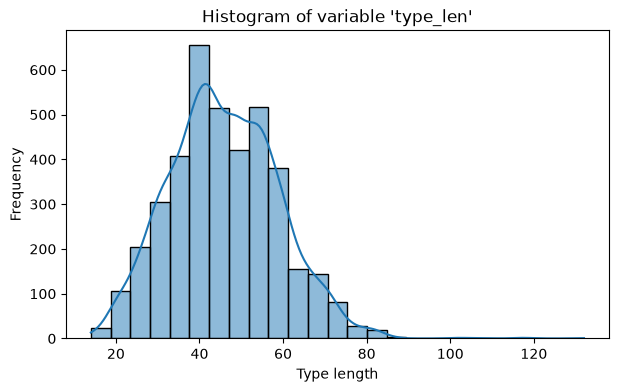

In [54]:
# New variable 'type_len' with the length of strings in 'type' (use .apply())
df['type_len'] = df['type'].apply(len)              #Zeichenanzahl jedes Textes in der neuen Spalte type_len speichern
                                                    #apply(len): wendet len() auf jeden Wert an; zählt auch Leerzeichen und Satzzeichen

# Display variables 'type' and 'type_len'
df[['type', 'type_len']].head()                     #Originaltext und Zeichenanzahl für die ersten fünf Zeilen anzeigen

# Plot histogram of variable 'type_len'
plt.figure(figsize=(7, 4)) #Neue Abbildung mit 7 × 4 Zoll erstellen
sns.histplot(df['type_len'], bins=25, kde=True)     #Textlängen in 25 Intervalle einteilen und Häufigkeiten als Balken darstellen
                                                    #kde=True: geglättete Dichtekurve zur Darstellung der Verteilungsform ergänzen
plt.title("Histogram of variable 'type_len'")       #Diagrammtitel setzen
plt.xlabel('Type length')                           #x-Achse beschriften: Zeichenanzahl der Texte
plt.ylabel('Frequency')                             #y-Achse beschriften: Anzahl Texte je Intervall
plt.show()                                          #Fertiges Diagramm anzeigen

### Create binary (0/1) variable 'luxury_car'

In [55]:
# Create a pattern which can be used to search the variable 'type'
pattern = ('BUGATTI|FERRARI|ROLLS-ROYCE|LAMBORGHINI|BENTLEY|ASTON MARTIN|'      #Gesuchte Luxusmarken festlegen; | bedeutet ODER
           'MASERATI|MCLAREN|PORSCHE')                                          #Python verbindet die beiden Texte automatisch zu einem Suchmuster

# Create new variable 'luxury_car' as binary dummy (0/1) variable
df['luxury_car'] = df['type'].str.contains(pat=pattern).astype(int)             #Enthält die Fahrzeugbezeichnung eine gesuchte Marke, wird luxury_car = 1, sonst 0
                                                                                #str.contains(pat=pattern): sucht die Marken aus pattern; Treffer → True, sonst False
                                                                                #astype(int): wandelt True in 1 und False in 0 um
                                                                                #Die Suche beachtet Gross-/Kleinschreibung: FERRARI trifft, Ferrari nicht

# Count the number of luxury cars
print(df['luxury_car'].sum())                                                   #Einsen addieren und damit die Anzahl der als Luxusauto markierten Fahrzeuge anzeigen

# Show values
df[['type', 'luxury_car']].loc[df['luxury_car'] == 1]                           #Nur Luxusautos mit Fahrzeugbezeichnung und 0/1-Markierung anzeigen
                                                                        #[[...]]: Spalten auswählen; .loc[...]: nur Zeilen behalten, deren luxury_car-Wert 1 ist

299


,type,luxury_car
8,PORSCHE 911 TURBO CABRIO PDK (CABRIOLET),1
26,FERRARI 348 TS (CABRIOLET),1
57,PORSCHE 911 SC (COUPÉ),1
64,PORSCHE 911 CARRERA 4S PDK (COUPÉ),1
65,PORSCHE 911 CARRERA 4S CABRIO (CABRIOLET),1
...,...,...
3933,FERRARI 458 ITALIA 4.5 V8 (COUPÉ),1
3934,FERRARI 458 ITALIA 4.5 V8 (COUPÉ),1
3958,PORSCHE 911 TURBO (S) CABRIO (CABRIOLET),1
3964,BENTLEY ARNAGE RED LABEL (LIMOUSINE),1


### Create variable 'price_per_hp'

In [56]:
# Create variable 'price_per_hp' (round to 2 decimal places)
df['price_per_hp'] = round(df['price'] / df['hp'], 2)   #Preis jedes Autos durch seine PS-Zahl teilen und als neue Spalte speichern
                                                        #round(..., 2): Preis pro PS auf zwei Nachkommastellen runden

# Display variables 'price', 'hp' and 'price_per_hp'
df[['price', 'hp', 'price_per_hp']].head()              #Preis, PS-Zahl und berechneten Preis pro PS für die ersten fünf Zeilen anzeigen
                                                        #[[...]]: Spalten als Tabelle auswählen; head(): erste fünf Zeilen

,price,hp,price_per_hp
0,22500,245,91.84
1,23749,184,129.07
2,18500,306,60.46
3,36000,360,100.0
4,48500,252,192.46


### Include current datetime as time stamp

In [57]:
# Include current datetime as time stamp in the format 'YYYY-MM-DD HH:MM:SS'
df['timestamp'] = datetime.now().strftime('%Y-%m-%d %H:%M:%S')  #Aktuellen Zeitpunkt als Text in jeder Zeile der neuen Spalte timestamp speichern
                                                                #datetime.now(): aktueller Zeitpunkt; strftime(): als Text formatieren
                                                                #%Y-%m-%d: Jahr-Monat-Tag; %H:%M:%S: Stunde:Minute:Sekunde
df['timestamp'].head()                                          #Zeitstempel der ersten fünf Zeilen anzeigen; alle erhalten denselben Zeitpunkt dieses Aufrufs

0    2026-10-16 23:36:59
1    2026-10-16 23:36:59
2    2026-10-16 23:36:59
3    2026-10-16 23:36:59
4    2026-10-16 23:36:59
Name: timestamp, dtype: str

## Discretization of numerical data

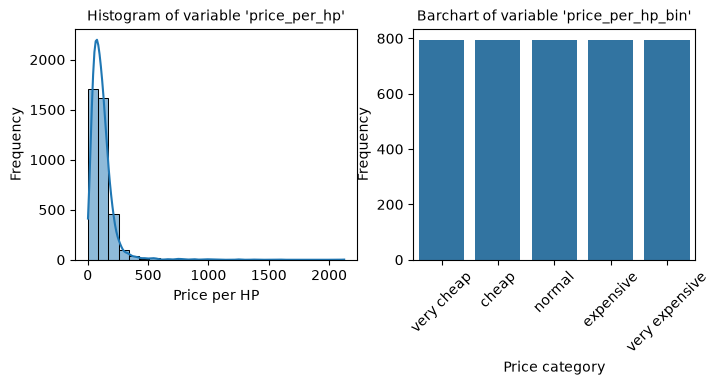

,price_per_hp,price_per_hp_bin
0,91.84,normal
1,129.07,expensive
2,60.46,cheap
3,100.0,normal
4,192.46,very expensive


In [58]:
# Discretization of the variable 'price_per_hp' into 5 bins
# (note the 'qcut' function)
df['price_per_hp_bin'] = pd.qcut(df['price_per_hp'],                    #Preis pro PS in geordnete Klassen einteilen und als neue Spalte speichern
                                 q=5,                                   #Fünf Klassen mit ungefähr gleich vielen Autos bilden; Grenzen anhand der Quantile bestimmen
                                 labels=['very cheap',                  #Beschriftung der niedrigsten Preisklasse
                                         'cheap',                       #Beschriftung der zweiten Klasse
                                         'normal',                      #Beschriftung der mittleren Klasse
                                         'expensive',                   #Beschriftung der vierten Klasse
                                         'very expensive'])             #Beschriftung der höchsten Preisklasse

# Show histogram of price_per_hp and barchart of variable 'price_per_hp_bin'
plt.figure(figsize=(8, 3))                                              #Neue Abbildung mit 8 × 3 Zoll erstellen

# Create a 1x2 grid
plt.subplot(1, 2, 1)                                                    #Raster mit einer Zeile und zwei Diagrammen erstellen; linkes Diagramm auswählen
sns.histplot(df['price_per_hp'], bins=25, kde=True)                     #Numerische Werte in 25 Intervalle einteilen und als Histogramm darstellen
                                                                        #kde=True: geglättete Kurve zur Verteilungsform ergänzen
plt.title("Histogram of variable 'price_per_hp'", fontsize=10)          #Diagrammtitel mit Schriftgrösse 10 setzen
plt.xlabel('Price per HP')                                              #x-Achse: Preis pro PS
plt.ylabel('Frequency')                                                 #y-Achse: Anzahl Autos je Zahlenintervall

plt.subplot(1, 2, 2)                                                    #Rechtes Diagramm im selben Raster auswählen
sns.countplot(data=df, x='price_per_hp_bin', orient='v')                #Autos je Preisklasse zählen und als vertikale Balken darstellen
plt.title("Barchart of variable 'price_per_hp_bin'", fontsize=10)       #Diagrammtitel mit Schriftgrösse 10 setzen
plt.xlabel('Price category')                                            #x-Achse: Preisklassen
plt.ylabel('Frequency')                                                 #y-Achse: Anzahl Autos je Klasse
plt.xticks(rotation=45)                                                 #Beschriftungen der x-Achse um 45 Grad drehen
plt.show()                                                              #Beide Diagramme anzeigen

# Display variables 'price_per_hp' and 'price_per_hp_bin'
df[['price_per_hp', 'price_per_hp_bin']].head()                         #Preis pro PS und zugeordnete Klasse für die ersten fünf Zeilen anzeigen

## One Hot Encoding

In [59]:
# One Hot Encoding of the variable 'price_per_hp_bin'
try:                                                                        #Versuchen, die Kategoriespalte in eigene Dummy-Spalten umzuwandeln
    df = pd.get_dummies(df,                                                 #Ergebnis in df speichern; ursprüngliche Kategoriespalte wird ersetzt
                        columns=['price_per_hp_bin'],                       #Für jede Preiskategorie eine eigene Spalte erstellen
                        drop_first=False)                                   #Alle Kategorien behalten; keine Dummy-Spalte weglassen
except KeyError:                                                            #Falls die angegebene Kategoriespalte nicht vorhanden ist
    print("Dummy variables already exist")                                  #Hinweis ausgeben; die Spalte könnte bereits umgewandelt worden sein
                                                                            #Die Meldung prüft nicht, ob Dummy-Spalten tatsächlich existieren

# Convert boolean values to integers (0 and 1)
dummy_cols = df.filter(like='price_per_hp_bin').columns                     #Namen aller Spalten sammeln, die price_per_hp_bin enthalten
df[dummy_cols] = df[dummy_cols].astype(int)                                 #Dummy-Werte in ganze Zahlen umwandeln: True → 1, False → 0

# Show values of the new dummy variables
df.filter(like='price_per_hp_bin').head()                                   #Erste fünf Zeilen der Dummy-Spalten anzeigen
                                                                            #filter(like=...): Spalten nach Namensteil auswählen; head(): erste fünf Zeilen

,price_per_hp_bin_very cheap,price_per_hp_bin_cheap,price_per_hp_bin_normal,price_per_hp_bin_expensive,price_per_hp_bin_very expensive
0,0,0,1,0,0
1,0,0,0,1,0
2,0,1,0,0,0
3,0,0,1,0,0
4,0,0,0,0,1


## Scaling

### Min-Max Scaling

#### By hand

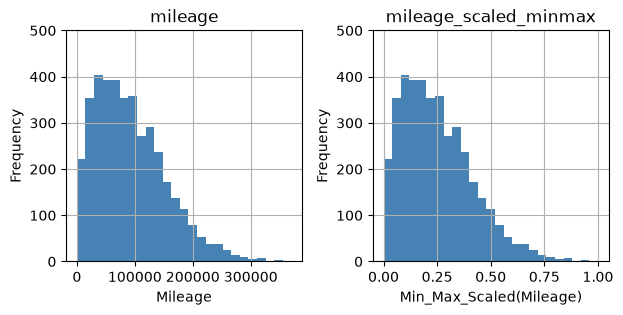

In [60]:
# Min-Max scaling of the variable 'mileage' (by hand)
df['mileage_scaled_minmax'] = ((df['mileage'] - df['mileage'].min())            #Von jedem Kilometerstand den kleinsten Kilometerstand abziehen
                               / (df['mileage'].max() - df['mileage'].min()))   #Durch die Spannweite teilen: grösster minus kleinster Kilometerstand
                                                                                #Ergebnis: kleinster Wert → 0, grösster → 1; übrige Werte dazwischen

# Histogram of the variable 'mileage' and 'mileage_scaled_minmax'
ax = df[['mileage', 'mileage_scaled_minmax']].hist(bins=25,                     #Originalwerte und skalierte Werte als zwei Histogramme darstellen
                                                   figsize=(7, 3),              #Gesamtgrösse der Abbildung: 7 × 3 Zoll
                                                   color='steelblue')           #Balkenfarbe festlegen; ax enthält die Diagrammachsen

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Min_Max_Scaled(Mileage)']):   #Jede Diagrammachse mit ihrer zugehörigen Beschriftung durchlaufen
                                                                                #flatten(): Achsenanordnung abflachen; zip(): Achsen und Beschriftungen paarweise verbinden
    axis.set_ylim(0, 500)                                                       #y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #x-Achse mit der jeweils zugehörigen Beschriftung versehen
    axis.set_ylabel('Frequency')                                                #y-Achse beschriften: Anzahl Autos je Intervall

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

#### scikit-learn version

In [61]:
# Min-Max scaling of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import MinMaxScaler                      #MinMaxScaler importieren: Werte standardmässig auf den Bereich 0 bis 1 skalieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = MinMaxScaler() #Scaler-Objekt für die Min-Max-Skalierung erstellen
df['mileage_scaled_minmax_sklearn'] = scaler.fit_transform(         #Skalierte Kilometerstände in neuer Spalte speichern
    df[['mileage']]).ravel()                                        #fit_transform(): Minimum und Maximum bestimmen und Werte auf 0 bis 1 skalieren
                                                                    #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                    #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df['mileage_scaled_minmax'],                      #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df['mileage_scaled_minmax_sklearn']))             #allclose(): Prüfen, ob alle Werte innerhalb kleiner numerischer Toleranzen übereinstimmen

True


### Max-Absolute Scaling

#### By hand

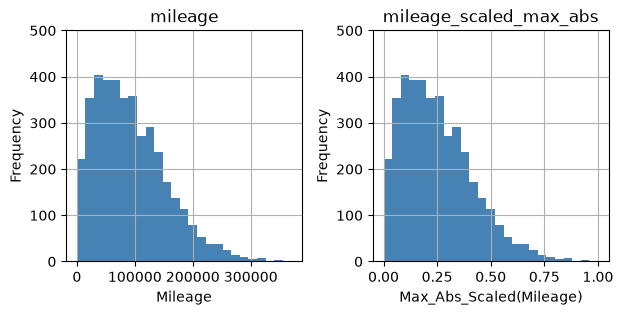

In [62]:
# Max-Absolute scaling of the variable 'mileage' (by hand)
df['mileage_scaled_max_abs'] = df['mileage'] / df['mileage'].abs().max()    #Jeden Kilometerstand durch den grössten Absolutwert dividieren
                                                                            #abs(): Absolutwerte bilden; max(): grössten Absolutwert bestimmen
                                                                            #Ergebnis: Werte zwischen -1 und 1 (bei positiven Kilometerständen 0 bis 1)
                                                                            #Erkenntnis: 0 bleibt 0; der grösste absolute Wert wird zu 1 oder -1
                                                                            #Im Gegensatz zu Min-Max wird kein Minimum abgezogen

# Histogram of the variable 'mileage' and 'mileage_scaled_max_abs'
ax = df[['mileage', 'mileage_scaled_max_abs']].hist(bins=25,                #Originale und skalierte Kilometerstände als zwei Histogramme darstellen
                                                    figsize=(7, 3),         #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                                    color='steelblue')      #bins=25: 25 Intervalle; color: Balkenfarbe
                                                                            #Erkenntnis: Skalierung verändert nur die Grössenordnung, nicht die Verteilungsform
                                                                            #Beide Histogramme haben deshalb dieselbe Form, aber unterschiedliche x-Achsenwerte

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Max_Abs_Scaled(Mileage)']):   #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse beschriften
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

#### scikit-learn version

In [63]:
# Max-Absolute scaling of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import MaxAbsScaler                  #MaxAbsScaler importieren: Werte durch den grössten Absolutwert skalieren (Bereich -1 bis 1)

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = MaxAbsScaler()                                         #Scaler-Objekt für die Max-Absolute-Skalierung erstellen
df['mileage_scaled_max_abs_sklearn'] = scaler.fit_transform(    #Skalierte Kilometerstände in neuer Spalte speichern
    df[['mileage']]).ravel()                                    #fit_transform(): Grössten Absolutwert bestimmen und alle Werte dadurch dividieren
                                                                #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df['mileage_scaled_max_abs'],                 #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df['mileage_scaled_max_abs_sklearn']))        #allclose(): Prüfen, ob alle Werte innerhalb kleiner numerischer Toleranzen übereinstimmen
                                                                #Ergebnis True: Beide Verfahren liefern praktisch identische Werte
                                                                #Erkenntnis: MaxAbsScaler() automatisiert die manuelle Max-Absolute-Skalierung
                                                                #Voraussetzung: Die Spalte 'mileage_scaled_max_abs' muss bereits existieren

True


### Robust Scaling

#### By hand

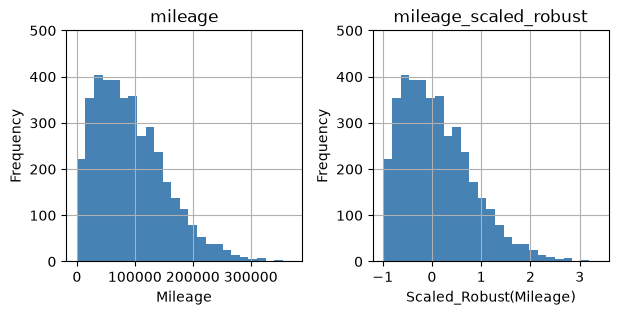

In [64]:
# Robust scaling of the variable 'mileage' (by hand)
df['mileage_scaled_robust'] = (df['mileage'] - df['mileage'].median()) / \
    (df['mileage'].quantile(0.75)                               #quantile(0.75): 75. Perzentil (Q3) bestimmen
     - df['mileage'].quantile(0.25))                            #quantile(0.25): 25. Perzentil (Q1) bestimmen
                                                                #median(): mittleren Kilometerstand bestimmen (50. Perzentil)
                                                                #Formel: (Wert - Median) / (Q3 - Q1); Q3 - Q1 = IQR
                                                                #Ergebnis: Median wird 0; Ausreisser beeinflussen die Skalierung weniger

# Histogram of the variable 'mileage' and 'mileage_scaled_robust'
ax = df[['mileage', 'mileage_scaled_robust']].hist(bins=25,         #Originale und robust skalierte Kilometerstände als zwei Histogramme darstellen
                                                   figsize=(7, 3),          #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                                   color='steelblue')       #hist(): Histogramme erstellen; bins=25: 25 Intervalle; color: Balkenfarbe
                                                                    #Erkenntnis: Verteilungsform bleibt gleich, x-Achse wird verschoben und skaliert
                                                                    #Werte können negativ oder grösser als 1 sein (kein fester Wertebereich)

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Scaled_Robust(Mileage)']): #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                    #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                           #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                          #set_xlabel(): x-Achse beschriften
    axis.set_ylabel('Frequency')                                    #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                          #Beide Histogramme anzeigen

#### scikit-learn version

In [65]:
# Robust scaling of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import RobustScaler  #RobustScaler importieren: Werte anhand von Median und IQR skalieren
                                                #(weniger empfindlich gegenüber Ausreissern)

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = RobustScaler()                                         #Scaler-Objekt für die robuste Skalierung erstellen
df['mileage_scaled_robust_sklearn'] = scaler.fit_transform(     #Robust skalierte Kilometerstände in neuer Spalte speichern
    df[['mileage']]).ravel()                                    #fit_transform(): Median und IQR bestimmen und Werte mit (Wert - Median) / IQR skalieren
                                                                #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df['mileage_scaled_robust'],                  #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df['mileage_scaled_robust_sklearn']))         #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen
                                                                #True: Beide Verfahren liefern praktisch identische Ergebnisse
                                                                #Erkenntnis: RobustScaler() automatisiert die manuelle Skalierung mit Median und IQR
                                                                #Der Median wird 0; Ausreisser bleiben erhalten, beeinflussen die Skalierung aber weniger
                                                                #Voraussetzung: Die manuell skalierte Spalte 'mileage_scaled_robust' muss bereits existieren

True


## Standardization

### Z-score Normalization

#### By hand

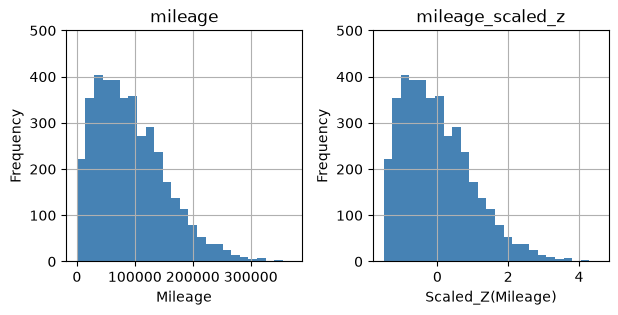

In [66]:
# Z-score Normalization of the variable 'mileage' (by hand)
df['mileage_scaled_z'] = ((df['mileage'] - df['mileage'].mean())    #Von jedem Kilometerstand den Mittelwert abziehen
                          / df['mileage'].std())                    #Durch die Standardabweichung dividieren
                                                                    #mean(): arithmetischen Mittelwert berechnen; std(): Standardabweichung bestimmen
                                                                    #Ergebnis: Mittelwert ≈ 0 und Standardabweichung ≈ 1
                                                                    #Werte über dem Mittelwert werden positiv, darunter negativ; kein fester Wertebereich

# Histogram of the variable 'mileage' and 'mileage_scaled_z'
ax = df[['mileage', 'mileage_scaled_z']].hist(bins=25,              #Originale und standardisierte Kilometerstände als zwei Histogramme darstellen
                                              figsize=(7, 3),       #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                              color='steelblue')    #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle; color: Balkenfarbe
                                                                    #Erkenntnis: Verteilungsform bleibt gleich, x-Achse wird verschoben und skaliert
                                                                    #Standardisierung erzeugt keine Normalverteilung, falls diese vorher nicht vorlag

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Scaled_Z(Mileage)']): #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                        #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                               #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                              #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                        #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                              #Beide Histogramme anzeigen

#### scikit-learn version

In [67]:
# Z-score Normalization of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import StandardScaler                #StandardScaler importieren: Werte auf Mittelwert 0 und Standardabweichung 1 standardisieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = StandardScaler() #Scaler-Objekt für die Z-Score-Standardisierung erstellen
df['mileage_scaled_z_sklearn'] = scaler.fit_transform(          #Standardisierte Kilometerstände in neuer Spalte speichern
    df[['mileage']]).ravel()                                    #fit_transform(): Mittelwert und Standardabweichung bestimmen und Werte standardisieren
                                                                #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Note: pandas .std() divides by n-1, StandardScaler divides by n,
# so the results differ slightly
print(np.allclose(df['mileage_scaled_z'],                       #Manuelle und sklearn-Standardisierung miteinander vergleichen
                  df['mileage_scaled_z_sklearn']))              #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen
                                                                #Erwartet False: pandas.std() verwendet n-1, StandardScaler verwendet n
                                                                #Erkenntnis: Unterschiedliche Berechnung der Standardabweichung führt zu leicht anderen Werten

# Check against the by-hand formula with the standard deviation
# divided by n (ddof=0)
z_ddof0 = (df['mileage'] - df['mileage'].mean()) / df['mileage'].std(ddof=0) #Z-Score manuell mit derselben Standardabweichung wie sklearn berechnen
                                                                             #std(ddof=0): Bei der Varianzberechnung durch n statt n-1 teilen
                                                                             #ddof: Freiheitsgradkorrektur; Standardwert bei pandas ist 1
print(np.allclose(z_ddof0, df['mileage_scaled_z_sklearn']))                  #Manuelle Berechnung mit ddof=0 und sklearn vergleichen
                                                                             #Erwartet True: Beide verwenden dieselbe Formel und liefern praktisch identische Werte

False
True


## Transformation

### Log-Transformation

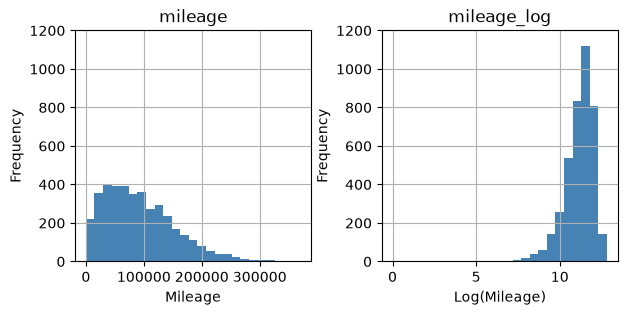

In [68]:
# Log-Transformation of the variable 'mileage'
df['mileage_log'] = np.log(df['mileage'])           #Kilometerstände logarithmieren und in neuer Spalte speichern
                                                    #np.log(): natürlichen Logarithmus (Basis e) für jeden Wert berechnen
                                                    #Voraussetzung: Werte müssen > 0 sein; log(0) ergibt -inf, negative Werte NaN
                                                    #Erkenntnis: Grosse Kilometerstände werden stärker komprimiert; Rechtsschiefe kann abnehmen

# Histogram of the variable 'mileage' and 'mileage_log'
ax = df[['mileage', 'mileage_log']].hist(bins=25,               #Originale und logarithmierte Kilometerstände als zwei Histogramme darstellen
                                         figsize=(7, 3),        #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                         color='steelblue')     #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle; color: Balkenfarbe
                                                                #Erkenntnis: Transformation kann die Verteilungsform verändern
                                                                #Rechtsschiefe kann reduziert werden; Normalverteilung ist nicht garantiert

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Log(Mileage)']):  #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                    #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 1200)                                          #set_ylim(): y-Achse auf 0 bis 1200 begrenzen
    axis.set_xlabel(label)                                          #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                    #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                          #Beide Histogramme anzeigen

### SQRT-Transformation

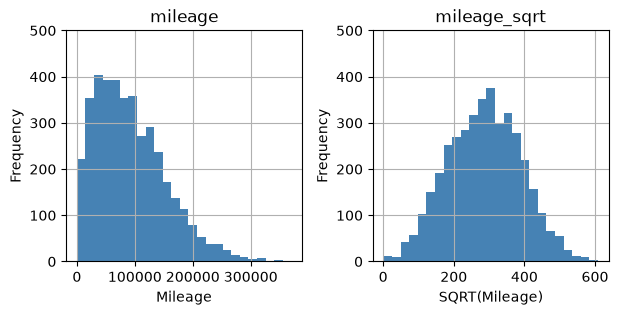

In [69]:
# SQRT-Transformation of the variable 'mileage'
df['mileage_sqrt'] = np.sqrt(df['mileage'])         #Quadratwurzel jedes Kilometerstands berechnen und in neuer Spalte speichern
                                                    #np.sqrt(): Quadratwurzel jedes Werts berechnen (z. B. √100 = 10)
                                                    #Voraussetzung: Werte müssen >= 0 sein; negative Werte ergeben NaN
                                                    #Erkenntnis: Grosse Werte werden stärker komprimiert als kleine; Rechtsschiefe kann abnehmen
                                                    #Im Gegensatz zu np.log() sind auch Nullwerte erlaubt (√0 = 0)

# Histogram of the variable 'mileage' and 'mileage_sqrt'
ax = df[['mileage', 'mileage_sqrt']].hist(bins=25,                  #Originale und wurzeltransformierte Kilometerstände als zwei Histogramme darstellen
                                          figsize=(7, 3),           #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                          color='steelblue')        #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle; color: Balkenfarbe
                                                                    #Erkenntnis: SQRT kann die Verteilungsform verändern und Rechtsschiefe reduzieren
                                                                    #Bei grossen Werten ist die Komprimierung schwächer als bei np.log()

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'SQRT(Mileage)']):     #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                        #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                               #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                              #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                        #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                              #Beide Histogramme anzeigen

### Box-Cox Transformation

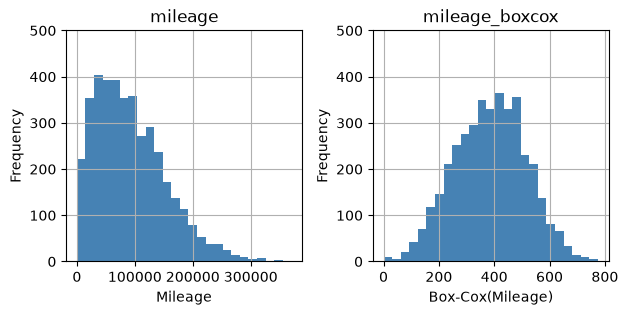

In [70]:
# Import the boxcox function from scipy
from scipy.stats import boxcox                          #boxcox() importieren: Box-Cox-Transformation zur Reduktion der Schiefe einer Verteilung

# Box-Cox Transformation of the variable 'mileage'
df['mileage_boxcox'], _ = boxcox(df['mileage'])         #Kilometerstände transformieren und in neuer Spalte speichern
                                                        #boxcox(): Transformationsparameter Lambda (λ) automatisch schätzen und Transformation durchführen
                                                        #Rückgabe: transformierte Werte und geschätztes Lambda; _ verwirft Lambda
                                                        #Voraussetzung: Alle Werte müssen > 0 sein (keine Nullwerte oder negativen Werte)
                                                        #Erkenntnis: Kann Rechtsschiefe reduzieren und die Verteilung einer Normalverteilung annähern
                                                        #Lambda bestimmt die Transformation: λ=0 entspricht log(x), λ=0.5 ist mit √x verwandt, λ=1 entspricht x−1

# Histogram of the variable 'mileage' and 'mileage_boxcox'
ax = df[['mileage', 'mileage_boxcox']].hist(bins=25,            #Originale und Box-Cox-transformierte Kilometerstände als zwei Histogramme darstellen
                                            figsize=(7, 3),     #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                            color='steelblue')  #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle; color: Balkenfarbe
                                                                #Erkenntnis: Box-Cox kann die Verteilungsform verändern und Schiefe reduzieren
                                                                #Eine Normalverteilung wird dadurch nicht garantiert

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Box-Cox(Mileage)']):      #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                            #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                                   #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                  #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                            #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                                  #Beide Histogramme anzeigen

## Combining & organizing data

### Reading car data with geocoded addresses

In [71]:
# Meaning of variables
# offer_id: unique identifier of the offer on autoscout24.ch
# lat: geographical latitude
# lon: geographical longitude
# bfs_number: official municipality id
# bfs_name: official municipality name
#offer_id: eindeutige Kennnummer eines Fahrzeugangebots auf autoscout24.ch
#lat: geografischer Breitengrad (Nord-Süd-Position)
#lon: geografischer Längengrad (Ost-West-Position)
#bfs_number: offizielle Gemeindenummer des Bundesamts für Statistik (BFS)
#bfs_name: offizieller Gemeindename gemäss BFS
#Erkenntnis: Geocodierte Daten ermöglichen die geografische Zuordnung von Fahrzeugangeboten

# Geocoded data (i.e. data with latitude and longitude)
df_geo = pd.read_csv('./autoscout24_data_geocoded.csv', #Geocodierte Fahrzeugdaten aus der CSV-Datei in den DataFrame df_geo einlesen
                     sep=';',                           #sep: Semikolon als Trennzeichen zwischen den Spalten verwenden
                     encoding='utf-8')                  #encoding: UTF-8-Zeichenkodierung für Sonderzeichen und Umlaute verwenden
                                                        #pd.read_csv(): CSV-Datei einlesen und als pandas-DataFrame zurückgeben
                                                        #./: Datei befindet sich im aktuellen Arbeitsverzeichnis (kein Data-Unterordner)

# Show data
df_geo.head()                                           #head(): Standardmässig die ersten 5 Zeilen anzeigen, um Spalten und Daten zu kontrollieren

,offer_id,lat,lon,bfs_number,bfs_name
0,7324420,47.434376,8.859333,228,Turbenthal
1,7512768,46.850327,7.200491,2293,Düdingen
2,7512034,46.386593,6.204862,5716,Eysins
3,7512728,47.542408,7.873130,4263,Zeiningen
4,7490242,47.067474,7.302120,306,Lyss


### Join geo-information to car data using .merge()

In [75]:
# Merge geo-information to the car data (the key is 'offer_id')
df2 = df.merge(df_geo[['offer_id',   #Nur die benötigten Spalten aus dem Geo-DataFrame auswählen
                       'lat',        #Geografischer Breitengrad (Nord-Süd-Position)
                       'lon',        #Geografischer Längengrad (Ost-West-Position)
                       'bfs_number', #Offizielle Gemeindenummer des Bundesamts für Statistik
                       'bfs_name']], #Offizieller Gemeindename
               on="offer_id",)       #merge(): Fahrzeugdaten und Geodaten über die gemeinsame Schlüsselspalte verbinden
                                     #on="offer_id": Fahrzeugangebote anhand ihrer eindeutigen Angebotsnummer zuordnen
                                     #Standardmässig how='inner': Nur Angebote mit übereinstimmender offer_id in beiden Tabellen übernehmen
                                     #df2: Neuer DataFrame mit Fahrzeugdaten und zusätzlichen geografischen Informationen
                                     #Erkenntnis: Die Fahrzeugdaten werden um lat, lon, bfs_number und bfs_name erweitert
                                     #Achtung: Fehlende Übereinstimmungen entfallen; doppelte Schlüssel können zusätzliche Zeilen erzeugen

# Show data
df2[['offer_id',            #Eindeutige Kennnummer des Fahrzeugangebots
     'type',                #Fahrzeugtyp bzw. Modellbezeichnung
     'price',               #Fahrzeugpreis
     'hp',                  #Motorleistung in PS
     'price_per_hp',        #Berechneter Preis pro PS
     'mileage',             #Kilometerstand
     'fuel_type',           #Treibstoffart
     'lat',                 #Geografischer Breitengrad
     'lon',                 #Geografischer Längengrad
     'bfs_number',          #Gemeindenummer
     'bfs_name']].head()    #Gewünschte Spalten auswählen und die ersten 5 Zeilen anzeigen
                            #Erkenntnis: Fahrzeugmerkmale und geografische Informationen stehen nun gemeinsam in einer Tabelle

,offer_id,type,price,hp,price_per_hp,mileage,fuel_type,lat,lon,bfs_number,bfs_name
0,7324420,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,22500,245,91.84,75000,Diesel,47.434376,8.859333,228,Turbenthal
1,7512768,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),23749,184,129.07,46655,Benzin,46.850327,7.200491,2293,Düdingen
2,7512034,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,18500,306,60.46,138955,Benzin,46.386593,6.204862,5716,Eysins
3,7512728,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,36000,360,100.0,43000,Benzin,47.542408,7.873130,4263,Zeiningen
4,7490242,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,48500,252,192.46,43300,Benzin,47.067474,7.302120,306,Lyss


### Reading municipality-level data from an .xlsx - file

In [76]:
# Meaning of variables:
# bfs_number: municipality id
# bfs_name: municipality name
# pop: number of residents
# pop_dens: population density per km2
# frg_pct: percentage foreigners
# emp: number of employees
#bfs_number: offizielle Gemeindenummer des Bundesamts für Statistik (BFS)
#bfs_name: offizieller Gemeindename
#pop: Anzahl Einwohner einer Gemeinde
#pop_dens: Bevölkerungsdichte (Einwohner pro km²)
#frg_pct: Anteil ausländischer Einwohner in Prozent
#emp: Anzahl Beschäftigte einer Gemeinde
#Erkenntnis: Gemeindedaten enthalten zusätzliche Merkmale, die über bfs_number mit anderen Daten kombiniert werden können

# Read municipality-level data from the .xlsx file
df_municip = pd.read_excel('./municipality_data.xlsx', #Excel-Datei mit Gemeindedaten aus dem aktuellen Arbeitsverzeichnis einlesen
                           sheet_name='data_for_import') #sheet_name: Das Excel-Tabellenblatt 'data_for_import' auswählen
                                                         #pd.read_excel(): Excel-Datei einlesen und als pandas-DataFrame zurückgeben
                                                         #df_municip: Neuer DataFrame mit den Merkmalen der Gemeinden
                                                         #./: Datei liegt im aktuellen Arbeitsverzeichnis (kein Data-Unterordner)

# Show data
df_municip.head(5) #head(5): Die ersten 5 Zeilen anzeigen, um Spaltennamen und Daten zu kontrollieren

,bfs_number,bfs_name,pop,pop_dens,frg_pct,emp
0,1,Aeugst am Albis,1981,250.442478,14.184755,442.0
1,2,Affoltern am Albis,12303,1161.756374,28.700317,6920.0
2,3,Bonstetten,5572,749.932705,16.564968,1014.0
3,4,Hausen am Albis,3751,275.808824,16.022394,1021.0
4,5,Hedingen,3778,578.560490,16.410799,1478.0


### Join municipality-level data to the car data data using .merge()

In [77]:
# Merge needs a key which must be identical in both data sets
# (here the key is 'bfs_number')
df3 = df2.merge(df_municip[['bfs_number',   #Nur die benötigten Spalten aus den Gemeindedaten auswählen
                            'pop',          #Anzahl Einwohner der Gemeinde
                            'pop_dens',     #Bevölkerungsdichte (Einwohner pro km²)
                            'frg_pct',      #Anteil ausländischer Einwohner in Prozent
                            'emp']],        #Anzahl Beschäftigte der Gemeinde
                on="bfs_number")            #merge(): Fahrzeug- und Geodaten (df2) mit Gemeindedaten (df_municip) verbinden
                                            #on="bfs_number": Gemeindenummer als gemeinsamen Schlüssel verwenden
                                            #Standardmässig how='inner': Nur Datensätze mit passender bfs_number in beiden DataFrames übernehmen
                                            #df3: Neuer DataFrame mit Fahrzeug-, Geo- und Gemeindedaten
                                            #Erkenntnis: Zweiter Merge ergänzt bestehende Fahrzeugdaten um demografische Gemeindemerkmale
                                            #Achtung: Fehlende Schlüsselübereinstimmungen entfallen; doppelte Schlüssel können Zeilen vervielfachen

# Show data
df3[['offer_id',        #Eindeutige Kennnummer des Fahrzeugangebots
     'type',            #Fahrzeugtyp bzw. Modell
     'price',           #Fahrzeugpreis
     'mileage',         #Kilometerstand
     'hp',              #Motorleistung in PS
     'price_per_hp',    #Berechneter Preis pro PS
     'fuel_type',       #Treibstoffart
     'lat',             #Geografischer Breitengrad
     'lon',             #Geografischer Längengrad
     'bfs_number',      #Offizielle Gemeindenummer
     'bfs_name',        #Offizieller Gemeindename
     'pop',             #Anzahl Einwohner der Gemeinde
     'pop_dens']].head() #Gewünschte Spalten auswählen und die ersten 5 Zeilen anzeigen
                         #Erkenntnis: df3 enthält nun Fahrzeugmerkmale, geografische Daten und Gemeindeinformationen
# Show data


,offer_id,type,price,mileage,hp,price_per_hp,fuel_type,lat,lon,bfs_number,bfs_name,pop,pop_dens
0,7324420,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,22500,75000,245,91.84,Diesel,47.434376,8.859333,228,Turbenthal,4883,193.616178
1,7512768,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),23749,46655,184,129.07,Benzin,46.850327,7.200491,2293,Düdingen,8181,265.962289
2,7512034,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,18500,138955,306,60.46,Benzin,46.386593,6.204862,5716,Eysins,1735,728.991597
3,7512728,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,36000,43000,360,100.0,Benzin,47.542408,7.873130,4263,Zeiningen,2381,209.410730
4,7490242,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,48500,43300,252,192.46,Benzin,47.067474,7.302120,306,Lyss,15525,1046.864464


### Sorting data

In [78]:
# Sorting data by 'price' and 'mileage' with highest price above
# (ascending=False)
df3 = df3.sort_values(by=['price', 'mileage'],  #sort_values(): DataFrame nach mehreren Spalten sortieren
                      ascending=False)          #ascending=False: Beide Spalten absteigend sortieren (grösste Werte zuerst)
                                                #Zuerst nach 'price' sortieren; bei gleichem Preis entscheidet 'mileage'
                                                #Erkenntnis: Teuerste Fahrzeuge stehen oben; bei gleichem Preis jene mit höherem Kilometerstand
                                                #df3 = ...: Sortiertes Ergebnis wieder in df3 speichern
                                                #Alternative: ascending=[False, True] → Preis absteigend, Kilometerstand aufsteigend

# Show data
df3[['offer_id',            #Eindeutige Kennnummer des Fahrzeugangebots
     'type',                #Fahrzeugtyp bzw. Modell
     'price',               #Fahrzeugpreis (primäres Sortierkriterium)
     'mileage',             #Kilometerstand (sekundäres Sortierkriterium)
     'hp',                  #Motorleistung in PS
     'price_per_hp',        #Berechneter Preis pro PS
     'fuel_type',           #Treibstoffart
     'lat',                 #Geografischer Breitengrad
     'lon',                 #Geografischer Längengrad
     'bfs_number',          #Offizielle Gemeindenummer
     'bfs_name',            #Offizieller Gemeindename
     'pop',                 #Anzahl Einwohner der Gemeinde
     'pop_dens']].head()    #Gewünschte Spalten auswählen und die ersten 5 Zeilen anzeigen
                            #Erkenntnis: Die fünf angezeigten Fahrzeuge gehören zu den teuersten Angeboten

,offer_id,type,price,mileage,hp,price_per_hp,fuel_type,lat,lon,bfs_number,bfs_name,pop,pop_dens
1434,6395032,PORSCHE 911 GT2 RS (COUPÉ),428000,8900,620,690.32,Benzin,46.618042,7.024349,2160,Vuadens,2435,233.014354
274,6978696,LAMBORGHINI AVENTADOR S LP740-4 ROADSTER E-GEA...,384900,4000,741,519.43,Benzin,47.354149,8.560637,261,Zürich,420217,4778.994655
2400,7448261,PORSCHE 911 SPEEDSTER MANUAL GEARBOX CHALK WHI...,379000,14,510,743.14,Benzin,46.533829,6.611891,5586,Lausanne,139408,3368.970517
3424,6768872,MCLAREN 675LT COUPÉ 3.8 V8 SSG (COUPÉ),280000,11500,675,414.81,Benzin,46.220200,6.145626,6621,Genève,203951,12810.992462
1612,5887777,MERCEDES-BENZ 220 SE (CABRIOLET),255000,1200,120,2125.0,Benzin,46.992401,8.310424,1507,Hergiswil (NW),5776,403.916084


### Reshaping data

#### Reshaping data using .stack() and .unstack()

In [79]:
# Create a subset of the data (first 5 rows)
df_sub = df3[['bfs_name', 'mileage', 'price', 'hp']][:5]    #Teilmenge des DataFrames erstellen: 4 ausgewählte Spalten und die ersten 5 Zeilen
                                                            #[['...']]: Gewünschte Spalten auswählen
                                                            #[:5]: Erste 5 Zeilen auswählen (Positionen 0 bis 4)
                                                            #Voraussetzung: df3 muss existieren und die angegebenen Spalten enthalten
print('Original shape')                                     #Überschrift für die ursprüngliche Tabellenstruktur ausgeben
print(df_sub, '\n')                                         #Teilmenge anzeigen; '\n' erzeugt einen zusätzlichen Zeilenumbruch

# Reshape the data using .stack()
df_sub_stacked = df_sub.stack()                             #stack(): Spalten in die Zeilenebene verschieben (DataFrame → Series)
                                                            #Ergebnis: Jeder ursprüngliche Zeilenindex wird mit den Spaltennamen kombiniert (MultiIndex)
                                                            #Bei 5 Zeilen und 4 Spalten entstehen normalerweise 20 Werte
                                                            #Standardmässig können fehlende Werte (NaN) beim Stacken entfallen
print('Stacked')                                            #Überschrift für die umstrukturierte Darstellung ausgeben
print(df_sub_stacked, '\n')                                 #Gestapelte Daten mit zweistufigem Index (MultiIndex) anzeigen

# Reshape the data back using .unstack()
print('Unstacked (= back to original shape)')               #Überschrift für die Rückumwandlung ausgeben
print(df_sub_stacked.unstack())                             #unstack(): Innere Indexebene wieder in Spalten umwandeln (Series → DataFrame)
                                                            #Ergebnis: Ursprüngliche Tabellenstruktur mit 5 Zeilen und 4 Spalten wiederherstellen
                                                            #Erkenntnis: stack() wandelt Spalten in Indexwerte um; unstack() macht dies rückgängig
                                                            #Achtung: Wenn stack() fehlende Werte entfernt, können diese beim unstack() als NaN zurückkehren

Original shape
            bfs_name  mileage   price   hp
1434         Vuadens     8900  428000  620
274           Zürich     4000  384900  741
2400        Lausanne       14  379000  510
3424          Genève    11500  280000  675
1612  Hergiswil (NW)     1200  255000  120 

Stacked
1434  bfs_name           Vuadens
      mileage               8900
      price               428000
      hp                     620
274   bfs_name            Zürich
      mileage               4000
      price               384900
      hp                     741
2400  bfs_name          Lausanne
      mileage                 14
      price               379000
      hp                     510
3424  bfs_name            Genève
      mileage              11500
      price               280000
      hp                     675
1612  bfs_name    Hergiswil (NW)
      mileage               1200
      price               255000
      hp                     120
dtype: object 

Unstacked (= back to original shape)
    

#### Reshaping data using .melt()

In [80]:
# Create a subset of the data (first 5 rows)
df_sub = df3[['mileage', 'price', 'hp']][:5]            #Teilmenge erstellen: 3 ausgewählte Spalten und die ersten 5 Zeilen
                                                        #[['mileage', 'price', 'hp']]: Gewünschte Spalten auswählen
                                                        #[:5]: Erste 5 Zeilen auswählen (Positionen 0 bis 4)
                                                        #Voraussetzung: df3 muss existieren und die angegebenen Spalten enthalten
print('Original shape')                                 #Überschrift für die ursprüngliche Tabellenstruktur ausgeben
print(df_sub, '\n')                                     #Originalen DataFrame anzeigen; '\n' erzeugt einen zusätzlichen Zeilenumbruch

# Reshape the data using .melt()
print('Reshaped using .melt()') #Überschrift für die umstrukturierte Darstellung ausgeben
print(pd.melt(df_sub, id_vars=['mileage'], value_vars=['price', 'hp']))     #melt(): Daten vom breiten (Wide) ins lange Format (Long) umwandeln
                                                                            #id_vars=['mileage']: Kilometerstand als Identifikationsvariable beibehalten
                                                                            #value_vars=['price', 'hp']: Diese beiden Spalten untereinander in Zeilen umwandeln
                                                                            #Ergebnis: 3 Spalten ('mileage', 'variable', 'value')
                                                                            #'variable': Enthält die ursprünglichen Spaltennamen ('price' oder 'hp')
                                                                            #'value': Enthält die zugehörigen Werte (Fahrzeugpreis bzw. Motorleistung)
                                                                            #Bei 5 ursprünglichen Zeilen und 2 value_vars entstehen 10 Zeilen
                                                                            #Erkenntnis: 'mileage' wird für jeden zugehörigen Wert wiederholt; keine Aggregation
                                                                            #Unterschied zu stack(): melt() erzeugt einen DataFrame mit normalen Spalten
                                                                            #statt einer Series mit MultiIndex

Original shape
      mileage   price   hp
1434     8900  428000  620
274      4000  384900  741
2400       14  379000  510
3424    11500  280000  675
1612     1200  255000  120 

Reshaped using .melt()
   mileage variable   value
0     8900    price  428000
1     4000    price  384900
2       14    price  379000
3    11500    price  280000
4     1200    price  255000
5     8900       hp     620
6     4000       hp     741
7       14       hp     510
8    11500       hp     675
9     1200       hp     120


### Pivoting data using .pivot_table()

In [81]:
# Create a pivot table with the mean values per fuel type
pivot_table = pd.pivot_table(                                       #pivot_table(): Daten nach Gruppen zusammenfassen und Kennzahlen aggregieren
    df3[['mileage', 'price', 'price_per_hp', 'hp', 'fuel_type']],   #Nur die benötigten Spalten aus dem DataFrame auswählen
    index=['fuel_type'],                                            #index: Nach Treibstoffart gruppieren (eine Zeile pro Treibstoffart)
    values={'price': np.mean,                                       #price: Durchschnittlichen Fahrzeugpreis je Treibstoffart berechnen
            'price_per_hp': np.mean,                                #price_per_hp: Durchschnittlichen Preis pro PS berechnen
            'hp': np.mean,                                          #hp: Durchschnittliche Motorleistung in PS berechnen
            'mileage': np.mean}).round(2)                           #mileage: Durchschnittlichen Kilometerstand berechnen; round(2): Auf 2 Dezimalstellen runden
                                                                    #WICHTIG: values bestimmt die auszuwertenden Spalten, nicht die Aggregationsfunktionen!
                                                                    #np.mean im values-Dictionary wird ignoriert; Mittelwert ist bereits die Standardaggregation
                                                                    #Unterschiedliche Aggregationsfunktionen werden über aggfunc={'price': np.mean, ...} festgelegt
                                                                    #Erkenntnis: Alle Fahrzeuge derselben Treibstoffart werden zu einer Zeile zusammengefasst
                                                                    #Beispiel: Alle Dieselfahrzeuge ergeben einen durchschnittlichen Preis, Kilometerstand und PS-Wert
                                                                    #Achtung: Fehlende numerische Werte (NaN) werden bei der Mittelwertberechnung ignoriert

# Format the values to 2 decimal places with trailing zeros
pivot_table = pivot_table.map(                                      #map(): Formatierungsfunktion auf jeden einzelnen Wert der Pivot-Tabelle anwenden
    lambda x: f"{x:.2f}" if isinstance(x, (int, float)) else x)     #lambda x: Anonyme Funktion, die jeden Tabellenwert verarbeitet
                                                                    #isinstance(): Prüft, ob x ein int oder float ist
                                                                    #f"{x:.2f}": Zahl mit genau 2 Nachkommastellen darstellen (z. B. 12500.50)
                                                                    #else x: Andere Werte unverändert übernehmen
                                                                    #Erkenntnis: Nachgestellte Nullen bleiben sichtbar (z. B. 12500.00 statt 12500.0)
                                                                    #Achtung: Formatierte Zahlen werden zu Text (str) und sind nicht mehr direkt numerisch berechenbar
                                                                    #Voraussetzung: DataFrame.map() ist ab pandas 2.1 verfügbar

# Display the pivot table
pivot_table #Pivot-Tabelle mit einer Zeile pro Treibstoffart und den durchschnittlichen Kennzahlen anzeigen
            #Erkenntnis: Ermöglicht den Vergleich von Preis, Kilometerstand und Motorleistung zwischen Treibstoffarten
            #Unterschied zu melt(): pivot_table() aggregiert Werte je Gruppe; melt() strukturiert Daten ohne Aggregation um

,hp,mileage,price,price_per_hp
fuel_type,,,,
Automat,304.00,76000.00,49000.00,161.18
Automatik-Getriebe,258.00,37800.00,79999.00,310.07
Benzin,245.38,89881.89,27344.08,112.76
Diesel,198.24,103766.03,24888.95,123.83
Elektro,457.79,59694.98,53093.18,138.80
Erdgas (CNG) / Benzin,85.00,50561.00,5900.00,69.41
Flüssiggas (LPG) / Benzin,97.00,83000.00,4800.00,49.48
Hybrid Benzin/Elektro,339.00,128356.00,19900.00,58.70
Hybrid Diesel/Elektro,261.00,263209.00,34000.00,130.27


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [ ]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-10-16 22:50:53
Python Version: 3.12.11
-----------------------------------
